<a href="https://colab.research.google.com/github/analicepinho/C-lculo-Num-rico/blob/main/AtividadeCN_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Atividade Prática 1 - Cálculo Numérico
Prof: Raquel J. Lobosco
Aluna: Analice Costa Pinho
Turma NB

In [2]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import Image as IPImage, display
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10

In [3]:
def erro_absoluto(x_ref, x_aprox):
    return np.abs(x_ref - x_aprox)

def erro_relativo(x_ref, x_aprox):
    return np.abs(x_ref - x_aprox) / np.abs(x_ref)

def erro_percentual(x_ref, x_aprox):
    return erro_relativo(x_ref, x_aprox) * 100.0

def truncar(x, n):
    fator = 10.0 ** n
    return math.trunc(x * fator) / fator

def arredondar(x, n):
    return round(x, n)

Parte A - truncamento e arredondamento

,Variável,Ref,n,Trunc,Ea_Trunc,Er_Trunc,Ep_Trunc(%),Arred,Ea_Arred,Er_Arred,Ep_Arred(%)
0,x1,3.141593,0,3.0000,0.141593,4.507034e-02,4.507034,3.0000,0.141593,4.507034e-02,4.507034
1,x1,3.141593,1,3.1000,0.041593,1.323935e-02,1.323935,3.1000,0.041593,1.323935e-02,1.323935
2,x1,3.141593,2,3.1400,0.001593,5.069562e-04,0.050696,3.1400,0.001593,5.069562e-04,0.050696
3,x1,3.141593,3,3.1410,0.000593,1.886464e-04,0.018865,3.1420,0.000407,1.296635e-04,0.012966
4,x1,3.141593,4,3.1415,0.000093,2.949141e-05,0.002949,3.1416,0.000007,2.339578e-06,0.000234
5,x2,98.765430,0,98.0000,0.765430,7.749979e-03,0.774998,99.0000,0.234570,2.375021e-03,0.237502
6,x2,98.765430,1,98.7000,0.065430,6.624788e-04,0.066248,98.8000,0.034570,3.500213e-04,0.035002
7,x2,98.765430,2,98.7600,0.005430,5.497875e-05,0.005498,98.7700,0.004570,4.627125e-05,0.004627
8,x2,98.765430,3,98.7650,0.000430,4.353750e-06,0.000435,98.7650,0.000430,4.353750e-06,0.000435
9,x2,98.765430,4,98.7654,0.000030,3.037500e-07,0.000030,98.7654,0.000030,3.037500e-07,0.000030


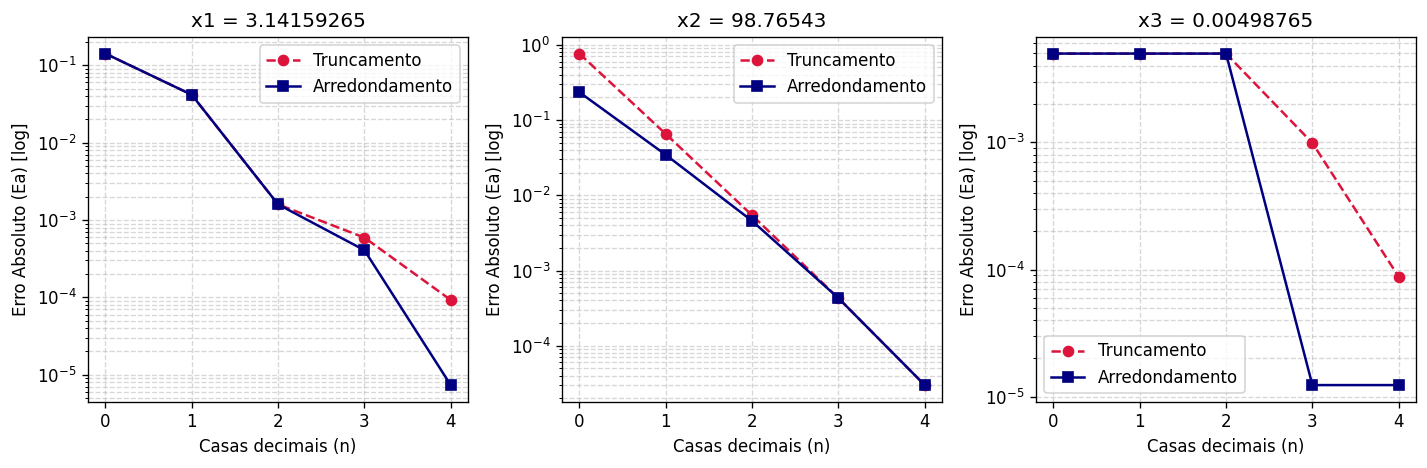

In [4]:
valores_A = {'x1': 3.14159265, 'x2': 98.76543, 'x3': 0.00498765}
casas = [0, 1, 2, 3, 4]

linhas_tabela_A = []

for nome, x_ref in valores_A.items():
    for n in casas:
        x_trunc = truncar(x_ref, n)
        x_arred = arredondar(x_ref, n)

        # Erros Truncamento
        ea_t = erro_absoluto(x_ref, x_trunc)
        er_t = erro_relativo(x_ref, x_trunc)
        ep_t = erro_percentual(x_ref, x_trunc)

        # Erros Arredondamento
        ea_a = erro_absoluto(x_ref, x_arred)
        er_a = erro_relativo(x_ref, x_arred)
        ep_a = erro_percentual(x_ref, x_arred)

        linhas_tabela_A.append({
            'Variável': nome, 'Ref': x_ref, 'n': n,
            'Trunc': x_trunc, 'Ea_Trunc': ea_t, 'Er_Trunc': er_t, 'Ep_Trunc(%)': ep_t,
            'Arred': x_arred, 'Ea_Arred': ea_a, 'Er_Arred': er_a, 'Ep_Arred(%)': ep_a
        })

df_A = pd.DataFrame(linhas_tabela_A)
display(df_A)

# Gráfico logarítmico de Ea em função de n
plt.figure(figsize=(12, 4))
for i, (nome, x_ref) in enumerate(valores_A.items(), 1):
    plt.subplot(1, 3, i)
    sub_df = df_A[df_A['Variável'] == nome]
    plt.plot(sub_df['n'], sub_df['Ea_Trunc'], 'o--', label='Truncamento', color='crimson')
    plt.plot(sub_df['n'], sub_df['Ea_Arred'], 's-', label='Arredondamento', color='navy')
    plt.yscale('log')
    plt.xlabel('Casas decimais (n)')
    plt.ylabel('Erro Absoluto (Ea) [log]')
    plt.title(f'{nome} = {x_ref}')
    plt.grid(True, which="both", ls="--", alpha=0.5)
    plt.legend()

plt.tight_layout()
plt.show()

**Arredondar sempre gera erro menor ou igual ao truncamento?**
A partir dos exemplos feitos, conclui-se que sim. Em todos os casos, o erro de arredondamento foi igual (quando o dígito desartado é menor que 5) ou menor.

Parte B - medidas de pressão arterial